# Phân loại phân khúc giá nhà Hà Nội bằng Random Forest

Notebook này đọc CSV, kiểm tra dữ liệu, tạo nhãn phân khúc từ giá, huấn luyện Random Forest, đánh giá và lưu mô hình để dùng trong ứng dụng Streamlit.

Quy ước nhãn: dưới 2 tỷ = Bình dân; 2 đến dưới 5 tỷ = Trung cấp; 5 đến 10 tỷ = Cao cấp; trên 10 tỷ = Hạng sang.

**Chú ý:** Giá nhà dùng để tạo nhãn nên không được dùng làm đầu vào. Không dùng các biến được tính trực tiếp từ giá như giá/m², vì sẽ gây target leakage.

## 1. Cài đặt và import thư viện

In [3]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [4]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from google.colab import files
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CLASS_ORDER = ["Bình dân", "Trung cấp", "Cao cấp", "Hạng sang"]
print("Thư viện đã sẵn sàng.")

Thư viện đã sẵn sàng.


## 2. Tải CSV và kiểm tra dữ liệu

In [5]:
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Không tìm thấy file CSV. Hãy tải lên file dữ liệu .csv.")
csv_path = csv_files[0]

def read_csv_flexible(path):
    last_error = None
    for enc in ["utf-8-sig", "utf-8", "cp1252", "latin1"]:
        try:
            return pd.read_csv(path, encoding=enc)
        except Exception as e:
            last_error = e
    raise last_error

df_raw = read_csv_flexible(csv_path)
print("File:", csv_path)
print("Kích thước:", df_raw.shape)
print("\nTên cột:", df_raw.columns.tolist())
display(df_raw.head())
print("\nKiểu dữ liệu:")
display(df_raw.dtypes.to_frame("Kiểu dữ liệu"))
print("\nGiá trị thiếu:")
display(pd.DataFrame({
    "Số lượng thiếu": df_raw.isna().sum(),
    "Tỷ lệ thiếu (%)": (df_raw.isna().mean() * 100).round(2)
}))
print("Số dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))

Saving VN_housing_dataset.csv to VN_housing_dataset.csv
File: VN_housing_dataset.csv
Kích thước: (82497, 13)

Tên cột: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2']


,Unnamed: 0,Ngày,Địa chỉ,Quận,Huyện,Loại hình nhà ở,Giấy tờ pháp lý,Số tầng,Số phòng ngủ,Diện tích,Dài,Rộng,Giá/m2
0,0.0,2020-08-05,"Đường Hoàng Quốc Việt, Phường Nghĩa Đô, Quận C...",Quận Cầu Giấy,Phường Nghĩa Đô,"Nhà ngõ, hẻm",Đã có sổ,4,5 phòng,46 m²,NaN,NaN,"86,96 triệu/m²"
1,1.0,2020-08-05,"Đường Kim Giang, Phường Kim Giang, Quận Thanh ...",Quận Thanh Xuân,Phường Kim Giang,"Nhà mặt phố, mặt tiền",NaN,NaN,3 phòng,37 m²,NaN,NaN,"116,22 triệu/m²"
2,2.0,2020-08-05,"phố minh khai, Phường Minh Khai, Quận Hai Bà T...",Quận Hai Bà Trưng,Phường Minh Khai,"Nhà ngõ, hẻm",Đã có sổ,4,4 phòng,40 m²,10 m,4 m,65 triệu/m²
3,3.0,2020-08-05,"Đường Võng Thị, Phường Thụy Khuê, Quận Tây Hồ,...",Quận Tây Hồ,Phường Thụy Khuê,"Nhà ngõ, hẻm",Đã có sổ,NaN,6 phòng,51 m²,12.75 m,4 m,100 triệu/m²
4,4.0,2020-08-05,"Đường Kim Giang, Phường Kim Giang, Quận Thanh ...",Quận Thanh Xuân,Phường Kim Giang,"Nhà ngõ, hẻm",NaN,NaN,4 phòng,36 m²,9 m,4 m,"86,11 triệu/m²"



Kiểu dữ liệu:


,Kiểu dữ liệu
Unnamed: 0,float64
Ngày,object
Địa chỉ,object
Quận,object
Huyện,object
Loại hình nhà ở,object
Giấy tờ pháp lý,object
Số tầng,object
Số phòng ngủ,object
Diện tích,object



Giá trị thiếu:


,Số lượng thiếu,Tỷ lệ thiếu (%)
Unnamed: 0,1,0.00
Ngày,1,0.00
Địa chỉ,48,0.06
Quận,2,0.00
Huyện,48,0.06
Loại hình nhà ở,32,0.04
Giấy tờ pháp lý,28887,35.02
Số tầng,46098,55.88
Số phòng ngủ,39,0.05
Diện tích,2,0.00


Số dòng trùng hoàn toàn: 0


## 3. Nhận diện cột giá và chuẩn hóa

In [6]:
def norm_text(value):
    s = str(value).strip().lower()
    replacements = {
        "á":"a","à":"a","ả":"a","ã":"a","ạ":"a","ă":"a","ắ":"a","ằ":"a","ẳ":"a","ẵ":"a","ặ":"a",
        "â":"a","ấ":"a","ầ":"a","ẩ":"a","ẫ":"a","ậ":"a","é":"e","è":"e","ẻ":"e","ẽ":"e","ẹ":"e",
        "ê":"e","ế":"e","ề":"e","ể":"e","ễ":"e","ệ":"e","í":"i","ì":"i","ỉ":"i","ĩ":"i","ị":"i",
        "ó":"o","ò":"o","ỏ":"o","õ":"o","ọ":"o","ô":"o","ố":"o","ồ":"o","ổ":"o","ỗ":"o","ộ":"o",
        "ơ":"o","ớ":"o","ờ":"o","ở":"o","ỡ":"o","ợ":"o","ú":"u","ù":"u","ủ":"u","ũ":"u","ụ":"u",
        "ư":"u","ứ":"u","ừ":"u","ử":"u","ữ":"u","ự":"u","ý":"y","ỳ":"y","ỷ":"y","ỹ":"y","ỵ":"y","đ":"d"
    }
    for a, b in replacements.items():
        s = s.replace(a, b)
    return re.sub(r"[^a-z0-9]+", "", s)

def find_column(columns, candidates):
    lookup = {norm_text(c): c for c in columns}
    for cand in candidates:
        if norm_text(cand) in lookup:
            return lookup[norm_text(cand)]
    for key, original in lookup.items():
        if any(norm_text(cand) in key for cand in candidates):
            return original
    return None

PRICE_COLUMN_OVERRIDE = None  # Nếu tự nhận diện sai, điền đúng tên cột giá, ví dụ "Price".
price_col = PRICE_COLUMN_OVERRIDE or find_column(
    df_raw.columns, ["Price", "Gia", "Gia ban", "Gia nha", "Gia bat dong san", "Gia VND"]
)
area_col = find_column(df_raw.columns, ["Area", "Dien tich", "Land Area", "Area m2"])
print("Cột giá nhận diện:", price_col)
print("Cột diện tích nhận diện:", area_col)
if price_col is None:
    raise ValueError("Không nhận diện được cột giá. Xem tên cột ở trên và sửa PRICE_COLUMN_OVERRIDE.")

def parse_numeric(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.number)):
        return float(value)
    s = str(value).strip().lower().replace("\xa0", "").replace(" ", "")
    if s in {"", "unknown", "nan", "none", "n/a", "-", "null"}:
        return np.nan
    s = re.sub(r"[^0-9,.-]", "", s)
    if not s or s in {".", ",", "-"}:
        return np.nan
    if "," in s and "." in s:
        if s.rfind(",") > s.rfind("."):
            s = s.replace(".", "").replace(",", ".")
        else:
            s = s.replace(",", "")
    elif "," in s:
        parts = s.split(",")
        if len(parts) > 2:
            s = "".join(parts[:-1]) + "." + parts[-1]
        elif len(parts[-1]) == 3:
            s = "".join(parts)
        else:
            s = s.replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return np.nan

def parse_price_to_billion(value):
    # Chuẩn hóa giá tổng thành tỷ VND; số thuần được suy đoán theo độ lớn.
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower().replace("\xa0", " ")
    num = parse_numeric(s)
    if pd.isna(num):
        return np.nan
    if "tỷ" in s or "ty" in s or "billion" in s:
        return num
    if "triệu" in s or "trieu" in s or "million" in s:
        return num / 1000
    if "nghìn" in s or "nghin" in s or "ngàn" in s:
        return num / 1_000_000
    if abs(num) >= 100_000_000:
        return num / 1_000_000_000
    if abs(num) >= 1_000:
        return num / 1_000
    return num

df = df_raw.copy()
df["_price_billion"] = df[price_col].apply(parse_price_to_billion)
print("Thống kê giá chuẩn hóa (tỷ đồng):")
display(df["_price_billion"].describe().to_frame("Giá (tỷ đồng)"))
print("Số giá không đọc được:", int(df["_price_billion"].isna().sum()))
display(pd.DataFrame({"Giá gốc": df[price_col].head(15), "Giá (tỷ đồng)": df["_price_billion"].head(15)}))

Cột giá nhận diện: Giấy tờ pháp lý
Cột diện tích nhận diện: Diện tích
Thống kê giá chuẩn hóa (tỷ đồng):


,Giá (tỷ đồng)
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


Số giá không đọc được: 82497


,Giá gốc,Giá (tỷ đồng)
0,Đã có sổ,NaN
1,NaN,NaN
2,Đã có sổ,NaN
3,Đã có sổ,NaN
4,NaN,NaN
5,Đã có sổ,NaN
6,NaN,NaN
7,Đã có sổ,NaN
8,NaN,NaN
9,Đã có sổ,NaN


## 4. Làm sạch cơ bản và tạo nhãn

Số dòng ban đầu: 82497
Số dòng hợp lệ: 82484
Số dòng bị loại: 13


,Số lượng,Tỷ lệ (%)
Phân khúc,,
Bình dân,6968,8.45
Trung cấp,54520,66.10
Cao cấp,15094,18.30
Hạng sang,5902,7.16


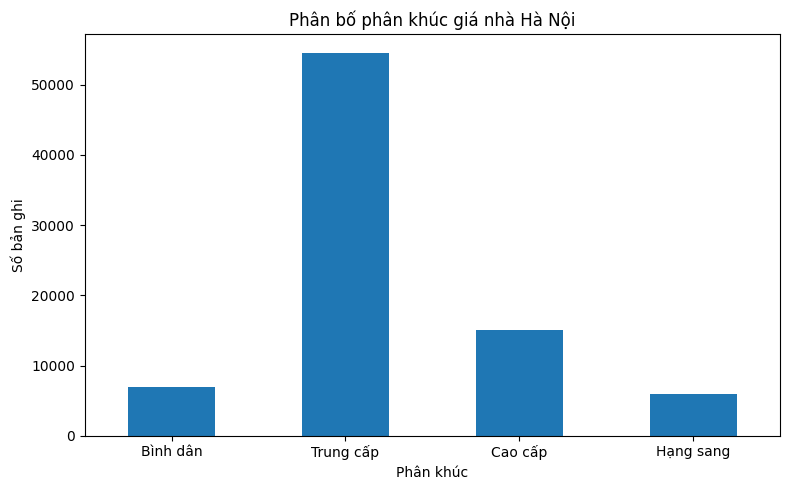

In [7]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

# Đọc file dữ liệu
df = pd.read_csv("VN_housing_dataset.csv")

# Chuyển diện tích, ví dụ "52.8 m²" hoặc "46 m²"
def parse_area(value):
    if pd.isna(value):
        return np.nan

    match = re.search(r"\d+(?:[.,]\d+)?", str(value))
    if not match:
        return np.nan

    return float(match.group().replace(",", "."))

# Chuyển giá/m², ví dụ "86,96 triệu/m²"
def parse_price_m2(value):
    if pd.isna(value):
        return np.nan

    match = re.search(r"\d+(?:[.,]\d+)?", str(value))
    if not match:
        return np.nan

    return float(match.group().replace(",", "."))

# Chuẩn hóa dữ liệu
df["area_m2"] = df["Diện tích"].apply(parse_area)
df["price_million_m2"] = df["Giá/m2"].apply(parse_price_m2)

# Tính tổng giá ước tính, đơn vị tỷ đồng
df["total_price_billion"] = (
    df["area_m2"] * df["price_million_m2"] / 1000
)

# Loại các bản ghi thiếu hoặc không hợp lệ
df_clean = df[
    df["area_m2"].gt(0)
    & df["price_million_m2"].gt(0)
    & df["total_price_billion"].notna()
].copy()

# Phân khúc giá nhà
df_clean["price_segment"] = pd.cut(
    df_clean["total_price_billion"],
    bins=[0, 2, 5, 10, np.inf],
    labels=["Bình dân", "Trung cấp", "Cao cấp", "Hạng sang"],
    right=True
)

# Thống kê kết quả
print("Số dòng ban đầu:", len(df))
print("Số dòng hợp lệ:", len(df_clean))
print("Số dòng bị loại:", len(df) - len(df_clean))

summary = (
    df_clean["price_segment"]
    .value_counts(sort=False)
    .rename_axis("Phân khúc")
    .to_frame("Số lượng")
)

summary["Tỷ lệ (%)"] = (
    summary["Số lượng"] / len(df_clean) * 100
).round(2)

display(summary)

# Vẽ biểu đồ
summary["Số lượng"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Phân bố phân khúc giá nhà Hà Nội")
plt.xlabel("Phân khúc")
plt.ylabel("Số bản ghi")
plt.tight_layout()
plt.show()


In [8]:

print("Các cột trong dữ liệu:")

print(df.columns.tolist())

print("\nCác cột trong dữ liệu đã làm sạch:")

print(df_clean.columns.tolist())


Các cột trong dữ liệu:
['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion']

Các cột trong dữ liệu đã làm sạch:
['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion', 'price_segment']


In [9]:
import pandas as pd
import numpy as np

# Tạo lại nhãn phân khúc giá nhà
df_clean["price_segment"] = pd.cut(
    df_clean["total_price_billion"],
    bins=[0, 2, 5, 10, np.inf],
    labels=[
        "Bình dân",
        "Trung cấp",
        "Cao cấp",
        "Hạng sang"
    ],
    right=True,
    include_lowest=True
)

# Kiểm tra cột đã được tạo
print(df_clean.columns.tolist())
print(df_clean["price_segment"].value_counts(dropna=False))

['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion', 'price_segment']
price_segment
Trung cấp    54520
Cao cấp      15094
Bình dân      6968
Hạng sang     5902
Name: count, dtype: int64


,Số lượng,Tỷ lệ (%)
Phân khúc,,
Bình dân,6968,8.45
Trung cấp,54520,66.10
Cao cấp,15094,18.30
Hạng sang,5902,7.16


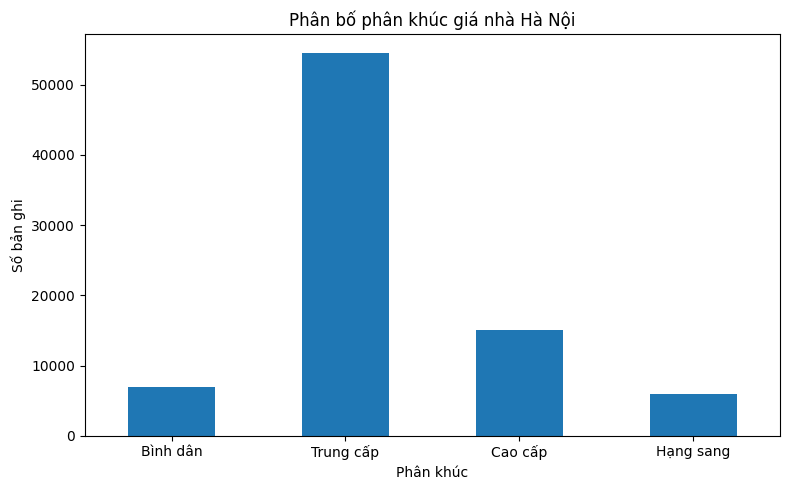

In [10]:
summary = (
    df_clean["price_segment"]
    .value_counts(sort=False)
    .reindex(
        ["Bình dân", "Trung cấp", "Cao cấp", "Hạng sang"],
        fill_value=0
    )
    .rename_axis("Phân khúc")
    .to_frame("Số lượng")
)

summary["Tỷ lệ (%)"] = (
    summary["Số lượng"] / len(df_clean) * 100
).round(2)

display(summary)

summary["Số lượng"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
    title="Phân bố phân khúc giá nhà Hà Nội"
)

import matplotlib.pyplot as plt
plt.xlabel("Phân khúc")
plt.ylabel("Số bản ghi")
plt.tight_layout()
plt.show()

Các cột hiện có: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion']

Số dòng ban đầu: 82497
Số dòng hợp lệ: 82484
Số dòng bị loại: 13

Các cột sau xử lý: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion', 'price_segment']


,Số lượng,Tỷ lệ (%)
Phân khúc,,
Bình dân,6968,8.45
Trung cấp,54520,66.10
Cao cấp,15094,18.30
Hạng sang,5902,7.16


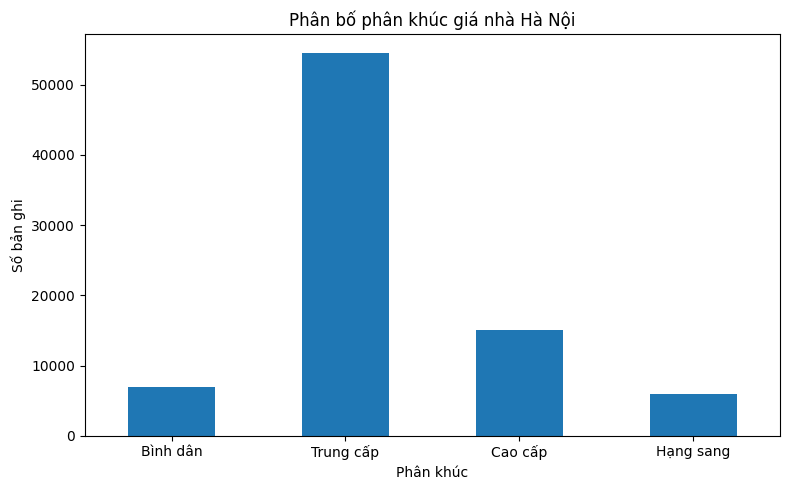

In [11]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

# 1. Kiểm tra dữ liệu đã được đọc chưa
if "df" not in globals():
    raise ValueError(
        "Chưa có dữ liệu df. Hãy chạy ô đọc file CSV trước."
    )

# 2. Tạo DataFrame mới từ dữ liệu gốc
df_clean = df.copy()

# 3. Kiểm tra các cột bắt buộc
print("Các cột hiện có:", df_clean.columns.tolist())

for col in ["Giá/m2", "Diện tích"]:
    if col not in df_clean.columns:
        raise ValueError(
            f"Không tìm thấy cột '{col}'. "
            "Hãy kiểm tra tên cột trong file CSV."
        )

# 4. Chuyển diện tích về số m²
def parse_area(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"\d+(?:[.,]\d+)?", str(value))
    return float(match.group().replace(",", ".")) if match else np.nan

# 5. Chuyển giá/m² về triệu đồng/m²
def parse_price(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"\d+(?:[.,]\d+)?", str(value))
    return float(match.group().replace(",", ".")) if match else np.nan

df_clean["area_m2"] = df_clean["Diện tích"].apply(parse_area)
df_clean["price_million_m2"] = df_clean["Giá/m2"].apply(parse_price)

# 6. Tính tổng giá ước tính, đơn vị tỷ đồng
df_clean["total_price_billion"] = (
    df_clean["area_m2"] * df_clean["price_million_m2"] / 1000
)

# 7. Giữ các dòng có diện tích và giá hợp lệ
df_clean = df_clean[
    df_clean["area_m2"].gt(0)
    & df_clean["price_million_m2"].gt(0)
    & df_clean["total_price_billion"].notna()
].copy()

# 8. TẠO CỘT price_segment TRƯỚC KHI THỐNG KÊ
df_clean["price_segment"] = pd.cut(
    df_clean["total_price_billion"],
    bins=[0, 2, 5, 10, np.inf],
    labels=["Bình dân", "Trung cấp", "Cao cấp", "Hạng sang"],
    right=True,
    include_lowest=True
)

# 9. In kết quả
print("\nSố dòng ban đầu:", len(df))
print("Số dòng hợp lệ:", len(df_clean))
print("Số dòng bị loại:", len(df) - len(df_clean))
print("\nCác cột sau xử lý:", df_clean.columns.tolist())

summary = (
    df_clean["price_segment"]
    .value_counts(sort=False)
    .reindex(["Bình dân", "Trung cấp", "Cao cấp", "Hạng sang"], fill_value=0)
    .rename_axis("Phân khúc")
    .to_frame("Số lượng")
)

summary["Tỷ lệ (%)"] = (
    summary["Số lượng"] / len(df_clean) * 100
).round(2) if len(df_clean) > 0 else 0

display(summary)

# 10. Vẽ biểu đồ
summary["Số lượng"].plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Phân bố phân khúc giá nhà Hà Nội")
plt.xlabel("Phân khúc")
plt.ylabel("Số bản ghi")
plt.tight_layout()
plt.show()


## 5. Chọn đặc trưng và tránh target leakage

In [12]:
# Cấm dùng cột giá, nhãn, URL, mô tả tự do, ID và biến giá/m² làm đầu vào.
excluded_name_parts = [
    "price", "gia", "segment", "phankhuc", "target", "label",
    "url", "link", "image", "thumbnail", "description", "mota",
    "content", "id", "phone", "email", "contact", "priceperm2",
    "priceper", "giatrenm2"
]
exclude_cols = {price_col, "_price_billion", "price_segment"}
candidate_cols = []
for col in df.columns:
    if col in exclude_cols:
        continue
    nc = norm_text(col)
    if any(norm_text(part) in nc for part in excluded_name_parts):
        continue
    candidate_cols.append(col)

usable_cols = []
for col in candidate_cols:
    s = df[col]
    if s.notna().sum() == 0 or s.nunique(dropna=True) <= 1:
        continue
    if s.dtype == "object" or pd.api.types.is_string_dtype(s):
        unique_ratio = s.nunique(dropna=True) / max(s.notna().sum(), 1)
        if s.nunique(dropna=True) > 100 and unique_ratio > 0.5:
            print("Loại cột văn bản độ duy nhất cao:", col)
            continue
    usable_cols.append(col)

if area_col is not None and area_col in df.columns and area_col not in usable_cols and df[area_col].nunique(dropna=True) > 1:
    usable_cols.append(area_col)

if not usable_cols:
    raise ValueError("Không tìm được đặc trưng phù hợp. Cần cột như diện tích, phòng ngủ, số tầng hoặc khu vực.")

X = df[usable_cols].copy()
y = df_clean["price_segment"].copy()

# Chuyển chuỗi có vẻ là số sang numeric khi ít nhất 80% giá trị đọc được.
for col in X.columns:
    if X[col].dtype == "object":
        converted = X[col].map(parse_numeric)
        nonmissing = X[col].notna().sum()
        if nonmissing and converted.notna().sum() / nonmissing >= 0.8:
            X[col] = converted

X = X.dropna(axis=1, how="all")
feature_columns = X.columns.tolist()
print("Số đặc trưng:", len(feature_columns))
print("Danh sách đặc trưng:", feature_columns)
display(X.head())
display(X.dtypes.to_frame("Kiểu dữ liệu"))

Số đặc trưng: 12
Danh sách đặc trưng: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'area_m2']


,Unnamed: 0,Ngày,Địa chỉ,Quận,Huyện,Loại hình nhà ở,Số tầng,Số phòng ngủ,Diện tích,Dài,Rộng,area_m2
0,0.0,2020-08-05,"Đường Hoàng Quốc Việt, Phường Nghĩa Đô, Quận C...",Quận Cầu Giấy,Phường Nghĩa Đô,"Nhà ngõ, hẻm",4.0,5.0,46.0,NaN,NaN,46.0
1,1.0,2020-08-05,"Đường Kim Giang, Phường Kim Giang, Quận Thanh ...",Quận Thanh Xuân,Phường Kim Giang,"Nhà mặt phố, mặt tiền",NaN,3.0,37.0,NaN,NaN,37.0
2,2.0,2020-08-05,"phố minh khai, Phường Minh Khai, Quận Hai Bà T...",Quận Hai Bà Trưng,Phường Minh Khai,"Nhà ngõ, hẻm",4.0,4.0,40.0,10.00,4.0,40.0
3,3.0,2020-08-05,"Đường Võng Thị, Phường Thụy Khuê, Quận Tây Hồ,...",Quận Tây Hồ,Phường Thụy Khuê,"Nhà ngõ, hẻm",NaN,6.0,51.0,12.75,4.0,51.0
4,4.0,2020-08-05,"Đường Kim Giang, Phường Kim Giang, Quận Thanh ...",Quận Thanh Xuân,Phường Kim Giang,"Nhà ngõ, hẻm",NaN,4.0,36.0,9.00,4.0,36.0


,Kiểu dữ liệu
Unnamed: 0,float64
Ngày,object
Địa chỉ,object
Quận,object
Huyện,object
Loại hình nhà ở,object
Số tầng,float64
Số phòng ngủ,float64
Diện tích,float64
Dài,float64


## 6. Chia train/test và huấn luyện Random Forest

In [13]:

from sklearn.model_selection import train_test_split

# 1. Kiểm tra các cột bắt buộc
print("Kích thước df_clean:", df_clean.shape)
print("Các cột:", df_clean.columns.tolist())

# 2. Loại các dòng không có nhãn phân khúc
data_model = df_clean.dropna(subset=["price_segment"]).copy()

# 3. Tạo y và X từ cùng một DataFrame
y = data_model["price_segment"].astype(str)

# Không dùng các cột tạo ra trực tiếp từ giá để dự đoán nhãn
exclude_cols = [
    "Giá/m2",
    "price_million_m2",
    "total_price_billion",
    "price_segment"
]

# Các cột diện tích và đặc trưng nhà vẫn được giữ lại
X = data_model.drop(
    columns=[c for c in exclude_cols if c in data_model.columns],
    errors="ignore"
)

# 4. Đồng bộ chỉ số để bảo đảm X và y cùng bản ghi
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

print("\nSố dòng X:", len(X))
print("Số dòng y:", len(y))
print("\nSố mẫu mỗi phân khúc:")
print(y.value_counts())

# 5. Chỉ giữ các lớp có ít nhất 2 mẫu để chia stratify
counts = y.value_counts()
valid_classes = counts[counts >= 2].index

mask = y.isin(valid_classes)
X = X.loc[mask].reset_index(drop=True)
y = y.loc[mask].reset_index(drop=True)

# 6. Chia tập train/test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nChia dữ liệu thành công!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Kích thước df_clean: (82484, 17)
Các cột: ['Unnamed: 0', 'Ngày', 'Địa chỉ', 'Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng', 'Giá/m2', 'area_m2', 'price_million_m2', 'total_price_billion', 'price_segment']

Số dòng X: 82484
Số dòng y: 82484

Số mẫu mỗi phân khúc:
price_segment
Trung cấp    54520
Cao cấp      15094
Bình dân      6968
Hạng sang     5902
Name: count, dtype: int64

Chia dữ liệu thành công!
X_train: (65987, 13)
X_test: (16497, 13)
y_train: (65987,)
y_test: (16497,)


In [14]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# 1. Loại cột ID nếu có
# Không dùng địa chỉ chi tiết để tránh mô hình học thuộc dữ liệu
X_train_model = X_train.drop(
    columns=["Unnamed: 0", "Địa chỉ"],
    errors="ignore"
).copy()

X_test_model = X_test.drop(
    columns=["Unnamed: 0", "Địa chỉ"],
    errors="ignore"
).copy()

# 2. Xử lý cột ngày
for data in [X_train_model, X_test_model]:
    if "Ngày" in data.columns:
        date = pd.to_datetime(data["Ngày"], errors="coerce", dayfirst=True)
        data["Nam_dang_tin"] = date.dt.year
        data["Thang_dang_tin"] = date.dt.month
        data["Ngay_trong_thang"] = date.dt.day
        data.drop(columns=["Ngày"], inplace=True)

# 3. Chuyển các cột số đang ở dạng chuỗi thành số nếu phù hợp
for col in X_train_model.columns:
    if X_train_model[col].dtype == "object":
        converted = pd.to_numeric(
            X_train_model[col], errors="coerce"
        )
        if converted.notna().mean() >= 0.9:
            X_train_model[col] = converted
            X_test_model[col] = pd.to_numeric(
                X_test_model[col], errors="coerce"
            )

# 4. Xác định các nhóm cột
numeric_cols = X_train_model.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = X_train_model.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Cột số:", numeric_cols)
print("Cột phân loại:", categorical_cols)

# 5. Tạo quy trình xử lý dữ liệu
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# 6. Tạo mô hình Random Forest
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 7. Huấn luyện
rf_model.fit(X_train_model, y_train)

print("\nHuấn luyện Random Forest thành công!")


Cột số: ['area_m2', 'Nam_dang_tin', 'Thang_dang_tin', 'Ngay_trong_thang']
Cột phân loại: ['Quận', 'Huyện', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'Số tầng', 'Số phòng ngủ', 'Diện tích', 'Dài', 'Rộng']

Huấn luyện Random Forest thành công!


## 7. Đánh giá mô hình

,Chỉ số,Giá trị
0,Accuracy,0.6294
1,Precision Macro,0.5335
2,Recall Macro,0.6944
3,F1-score Macro,0.5708



Báo cáo chi tiết:
              precision    recall  f1-score   support

    Bình dân       0.36      0.81      0.50      1394
     Cao cấp       0.42      0.53      0.47      3019
   Hạng sang       0.45      0.83      0.58      1180
   Trung cấp       0.90      0.61      0.73     10904

    accuracy                           0.63     16497
   macro avg       0.53      0.69      0.57     16497
weighted avg       0.73      0.63      0.65     16497



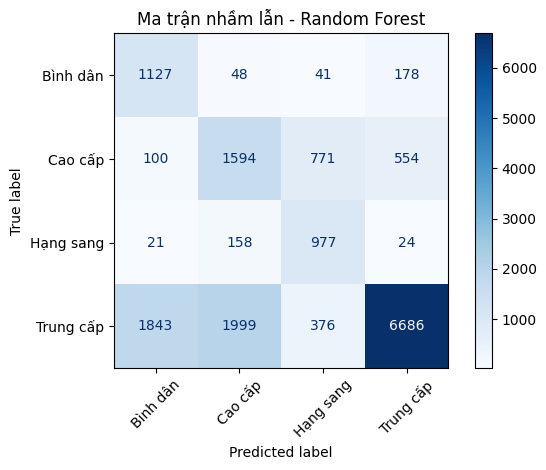

In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Dự đoán trên tập kiểm thử
y_pred = rf_model.predict(X_test_model)

# Tính các chỉ số
metrics = pd.DataFrame({
    "Chỉ số": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-score Macro"
    ],
    "Giá trị": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ]
})

display(metrics.style.format({"Giá trị": "{:.4f}"}))

print("\nBáo cáo chi tiết:")
print(classification_report(y_test, y_pred, zero_division=0))

# Ma trận nhầm lẫn
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Ma trận nhầm lẫn - Random Forest")
plt.tight_layout()
plt.show()


In [16]:
print("rf_model:", "rf_model" in globals())
print("model:", "model" in globals())
print("X_train_model:", "X_train_model" in globals())
print("y_train:", "y_train" in globals())

rf_model: True
model: False
X_train_model: True
y_train: True


In [17]:
import joblib
from sklearn.metrics import accuracy_score, f1_score

y_pred = rf_model.predict(X_test_model)

bundle = {
    "model": rf_model,
    "feature_columns": X_train_model.columns.tolist(),
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "class_names": rf_model.classes_.tolist(),
    "metrics": {
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    }
}

joblib.dump(bundle, "house_price_rf_bundle.joblib")

print("Đã lưu mô hình thành công!")
print("Accuracy:", round(bundle["metrics"]["accuracy"], 4))
print("Macro F1:", round(bundle["metrics"]["f1_macro"], 4))

Đã lưu mô hình thành công!
Số đặc trưng: 13
Các đặc trưng dạng số: ['area_m2', 'Nam_dang_tin', 'Thang_dang_tin', 'Ngay_trong_thang']
Accuracy: 0.6294
Macro F1: 0.5708


## 8. Độ quan trọng của đặc trưng

Top 20 đặc trưng quan trọng nhất:


,Đặc trưng,Độ quan trọng
0,num__area_m2,0.181823
338,"cat__Loại hình nhà ở_Nhà ngõ, hẻm",0.102836
337,"cat__Loại hình nhà ở_Nhà mặt phố, mặt tiền",0.086696
371,cat__Số phòng ngủ_2 phòng,0.053390
372,cat__Số phòng ngủ_3 phòng,0.037669
186,cat__Huyện_Phường Yên Nghĩa,0.029530
373,cat__Số phòng ngủ_4 phòng,0.027274
26,cat__Quận_Quận Hà Đông,0.022441
336,cat__Loại hình nhà ở_Nhà biệt thự,0.017601
503,cat__Diện tích_20 m²,0.014036


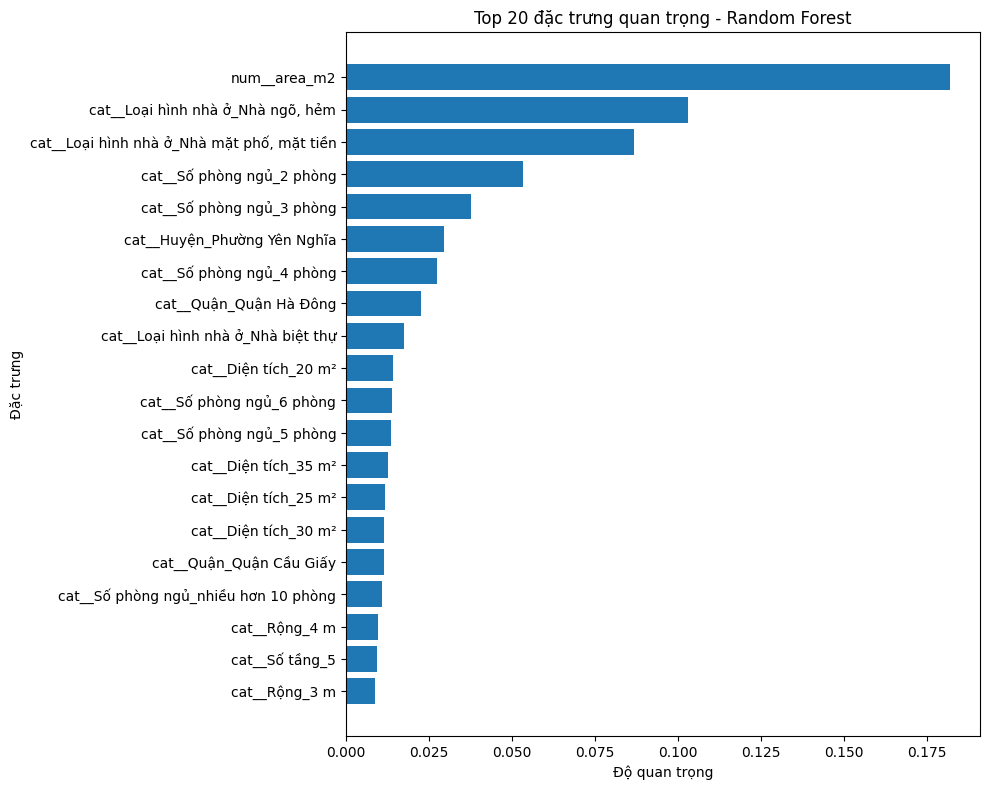

,Đặc trưng,Importance
0,num__area_m2,0.181823
338,"cat__Loại hình nhà ở_Nhà ngõ, hẻm",0.102836
337,"cat__Loại hình nhà ở_Nhà mặt phố, mặt tiền",0.086696
371,cat__Số phòng ngủ_2 phòng,0.053390
372,cat__Số phòng ngủ_3 phòng,0.037669
186,cat__Huyện_Phường Yên Nghĩa,0.029530
373,cat__Số phòng ngủ_4 phòng,0.027274
26,cat__Quận_Quận Hà Đông,0.022441
336,cat__Loại hình nhà ở_Nhà biệt thự,0.017601
503,cat__Diện tích_20 m²,0.014036


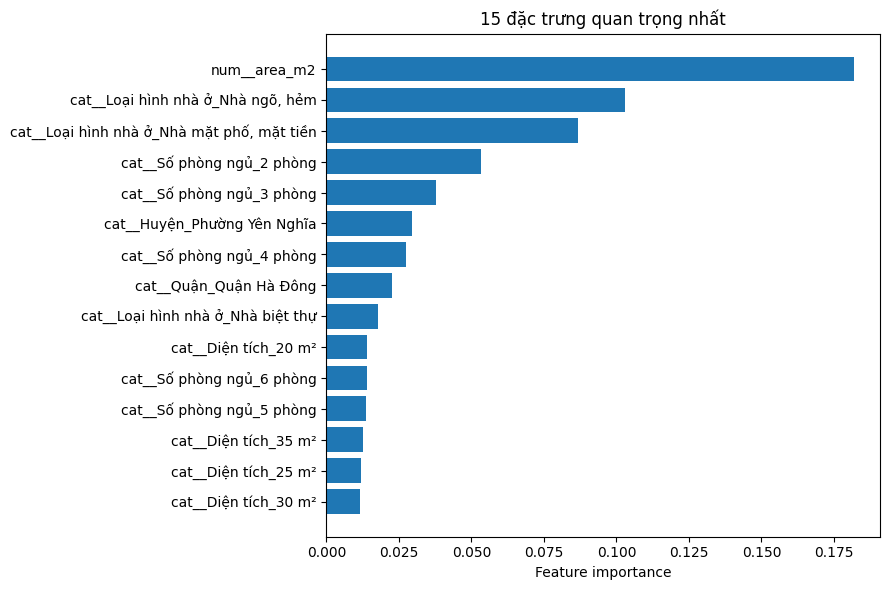

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

# Dùng đúng tên mô hình đã huấn luyện
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_rf = rf_model.named_steps["classifier"]

# Lấy tên đặc trưng sau tiền xử lý
names_out = fitted_preprocessor.get_feature_names_out()

# Lấy độ quan trọng của từng đặc trưng
importance_df = pd.DataFrame({
    "Đặc trưng": names_out,
    "Độ quan trọng": fitted_rf.feature_importances_
})

# Sắp xếp từ cao xuống thấp
importance_df = importance_df.sort_values(
    by="Độ quan trọng",
    ascending=False
)

print("Top 20 đặc trưng quan trọng nhất:")
display(importance_df.head(20))

# Vẽ biểu đồ Top 20
top20 = importance_df.head(20).sort_values(
    "Độ quan trọng",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(top20["Đặc trưng"], top20["Độ quan trọng"])
plt.xlabel("Độ quan trọng")
plt.ylabel("Đặc trưng")
plt.title("Top 20 đặc trưng quan trọng - Random Forest")
plt.tight_layout()
plt.show()

try:
    names_out = fitted_preprocessor.get_feature_names_out()
    importance_df = pd.DataFrame({
        "Đặc trưng": names_out,
        "Importance": fitted_rf.feature_importances_
    }).sort_values("Importance", ascending=False)
    display(importance_df.head(20))
    top = importance_df.head(15).sort_values("Importance")
    plt.figure(figsize=(9,6))
    plt.barh(top["Đặc trưng"], top["Importance"])
    plt.xlabel("Feature importance")
    plt.title("15 đặc trưng quan trọng nhất")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Không thể lấy tên đặc trưng:", e)

## 9. Thử dự đoán trên mẫu test

In [19]:
# Dự đoán 10 mẫu trong tập kiểm tra
demo = X_test_model.head(10).copy()

# Gắn nhãn thực tế và nhãn dự đoán
demo["Nhãn thực tế"] = y_test.iloc[:10].to_numpy()
demo["Nhãn dự đoán"] = rf_model.predict(
    X_test_model.head(10)
)

# Kiểm tra dự đoán đúng hay sai
demo["Kết quả"] = (
    demo["Nhãn thực tế"] == demo["Nhãn dự đoán"]
).map({True: "Đúng", False: "Sai"})

display(demo)

,Quận,Huyện,Loại hình nhà ở,Giấy tờ pháp lý,Số tầng,Số phòng ngủ,Diện tích,Dài,Rộng,area_m2,Nam_dang_tin,Thang_dang_tin,Ngay_trong_thang,Nhãn thực tế,Nhãn dự đoán,Kết quả
67634,Quận Thanh Xuân,Phường Khương Đình,"Nhà ngõ, hẻm",NaN,NaN,3 phòng,36 m²,NaN,NaN,36.0,2020,6,18,Trung cấp,Trung cấp,Đúng
25446,Quận Hai Bà Trưng,Phường Vĩnh Tuy,"Nhà ngõ, hẻm",NaN,NaN,4 phòng,45 m²,NaN,NaN,45.0,2020,7,21,Trung cấp,Trung cấp,Đúng
70816,Quận Hai Bà Trưng,Phường Bạch Đằng,"Nhà ngõ, hẻm",NaN,NaN,4 phòng,49 m²,NaN,NaN,49.0,2020,6,16,Trung cấp,Cao cấp,Sai
56798,Quận Cầu Giấy,Phường Nghĩa Tân,"Nhà ngõ, hẻm",Đã có sổ,5,6 phòng,58 m²,NaN,5 m,58.0,2020,6,26,Cao cấp,Cao cấp,Đúng
25423,Quận Hai Bà Trưng,Phường Bạch Mai,"Nhà mặt phố, mặt tiền",NaN,NaN,3 phòng,35 m²,NaN,NaN,35.0,2020,7,21,Trung cấp,Trung cấp,Đúng
67230,Quận Hai Bà Trưng,Phường Bạch Đằng,"Nhà ngõ, hẻm",NaN,NaN,3 phòng,32 m²,NaN,NaN,32.0,2020,6,18,Trung cấp,Trung cấp,Đúng
10448,Quận Hai Bà Trưng,Phường Vĩnh Tuy,"Nhà mặt phố, mặt tiền",Đã có sổ,6,nhiều hơn 10 phòng,56 m²,158 m,36 m,56.0,2020,7,30,Hạng sang,Hạng sang,Đúng
60571,Quận Nam Từ Liêm,Phường Mỹ Đình 1,"Nhà ngõ, hẻm",Đã có sổ,6,nhiều hơn 10 phòng,65 m²,NaN,NaN,65.0,2020,6,23,Cao cấp,Cao cấp,Đúng
279,Quận Hà Đông,Phường Vạn Phúc,"Nhà ngõ, hẻm",Đã có sổ,5,3 phòng,30 m²,10 m,3.2 m,30.0,2020,8,4,Trung cấp,Bình dân,Sai
20184,Quận Long Biên,Phường Thạch Bàn,Nhà phố liền kề,NaN,NaN,4 phòng,92 m²,14 m,7 m,92.0,2020,7,24,Cao cấp,Hạng sang,Sai


## 10. Lưu mô hình cho ứng dụng Streamlit

In [22]:

import joblib
from sklearn.metrics import accuracy_score, f1_score

y_pred = rf_model.predict(X_test_model)

bundle = {
    "model": rf_model,
    "feature_columns": X_train_model.columns.tolist(),
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "class_names": rf_model.classes_.tolist(),
    "metrics": {
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    }
}

joblib.dump(bundle, "house_price_rf_bundle.joblib")

print("Đã lưu mô hình thành công!")
print("Accuracy:", round(bundle["metrics"]["accuracy"], 4))
print("Macro F1:", round(bundle["metrics"]["f1_macro"], 4))


Đã lưu mô hình thành công!
Accuracy: 0.6294
Macro F1: 0.5708


In [24]:
import joblib

print("File mô hình đã lưu:", joblib.os.path.exists("house_price_rf_bundle.joblib"))

File mô hình đã lưu: True


In [25]:
from google.colab import files
files.download("house_price_rf_bundle.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Gợi ý kết luận báo cáo
Sau khi chạy, ghi số liệu thực tế: kích thước dữ liệu, tỷ lệ mỗi lớp, Accuracy, Macro F1, lớp có F1 thấp, các đặc trưng quan trọng và hạn chế. Không tự điền số liệu khi chưa chạy.